# Feature extraction:



In [2]:
import numpy as np
import matplotlib.pyplot as plt

from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.SeqUtils import ProtParamData 
from aaindex_parse import parse_aaindex_file

from pathlib import Path

# repository root: go up from the notebook folder until Data_preparation/ is found
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Data_preparation').is_dir())

In [3]:
with open(ROOT / 'Feature_Selection' / 'AAindex_scales.txt','r') as f:
    dict_f={}
    for line in f:
        line=line.strip().split()
        dict_f[line[1]]=parse_aaindex_file(ROOT / 'Feature_Selection' / 'aaindex1',line[0])

#Amino acid scale: Transmembrane tendency ProtScale

dict_f['tt'] = {
    'A':  0.380,  # Ala
    'R': -2.570,  # Arg
    'N': -1.620,  # Asn
    'D': -3.270,  # Asp
    'C': -0.300,  # Cys
    'Q': -1.840,  # Gln
    'E': -2.900,  # Glu
    'G': -0.190,  # Gly
    'H': -1.440,  # His
    'I':  1.970,  # Ile
    'L':  1.820,  # Leu
    'K': -3.460,  # Lys
    'M':  1.400,  # Met
    'F':  1.980,  # Phe
    'P': -1.440,  # Pro
    'S': -0.530,  # Ser
    'T': -0.320,  # Thr
    'W':  1.530,  # Trp
    'Y':  0.490,  # Tyr
    'V':  1.460,  # Val
}

---
# Encoding



In [4]:
def profile_stat(profile):
    return max(profile),np.argmax(profile)/40

In [5]:
from collections import Counter

AA_keys="ACDEFGHIKLMNPQRSTVWY"
N_TER=22 # composition window = median SP length in the training set (22 in every CV split)
def count_aa(seq):

    dict_aa= Counter({aa: 0 for aa in AA_keys})

    for aa in seq:
        if aa in AA_keys:
            dict_aa[aa]+=1

    # fixed column order (A,C,D,...) and frequencies instead of raw counts
    return [dict_aa[aa]/len(seq) for aa in AA_keys]

In [ ]:
def profile(sequence, scale, w):
    # one value per residue; ends and unknown residues handled with the shrinking window
    L = len(sequence)
    d = w // 2
    profile = []
    for i in range(L):
        window = []
        for j in range(i - d, i + d + 1):
            if 0 <= j < L and sequence[j] in scale:     # inside the sequence AND a known residue
                window.append(scale[sequence[j]])
        profile.append(sum(window) / len(window) if window else np.nan) #append the mean 
    return np.array(profile)

In [7]:
def extract_f(seq,dict_f):

    #______kd_________
    kd=profile(seq[:40],dict_f['kd'],5)
    kd_max,kd_max_p=profile_stat(kd)
    kd_th=2 #decision from literature
    kd_len = 0

    if kd_max>=kd_th:

        i=int(kd_max_p*40)

        kd_len=0
        while i<len(kd) and kd[i]>=kd_th:
            kd_len+=1
            i+=1

        i=int(kd_max_p*40-1)
        while i>=0 and kd[i]>=kd_th:
            kd_len+=1
            i-=1

    kd_dekay=kd_max-kd[-1]





    #______charge_________
    charge_pos=profile(seq[:40],dict_f['p'],3)
    max_charge_pos,max_charge_pos_p=profile_stat(charge_pos)

    charge_neg=profile(seq[:40],dict_f['n'],3)
    max_charge_neg,max_charge_neg_p=profile_stat(charge_neg)

    #_____nfh_&_nfb____________
    nfh=profile(seq[:40],dict_f['nfh'],9)
    max_nfh,max_nfh_p=profile_stat(nfh)

    nfb=profile(seq[:40],dict_f['nfb'],9)
    max_nfb,max_nfb_p=profile_stat(nfb)

    #____res_vol_____
    res_vol_mean=np.mean(profile(seq[:40],dict_f['v'],5))

    #____signal_seq_h_potential
    signal=profile(seq[:40],dict_f['s'],9)
    signal_max,signal_max_p=profile_stat(signal)

    #___flexibility___
    flexibility_mean=np.mean(profile(seq[:40],dict_f['f'],9))


    #___mut____
    mut_mean=np.mean(profile(seq[:40],dict_f['rm'],9))


    #___N-ter_comp_____
    n_ter_comp=count_aa(seq[:N_TER])

    return [kd_max,kd_max_p,kd_len,kd_dekay,max_charge_pos,max_charge_pos_p,max_charge_neg,max_charge_neg_p,max_nfh,max_nfh_p,max_nfb,max_nfb_p,res_vol_mean,signal_max,signal_max_p,flexibility_mean,mut_mean]+n_ter_comp

In [8]:
with open('feature.csv','w') as feature_file:
    print('id,max_kd,p_max_kd,kd_len,kd_dakay,max_charge_pos,max_charge_pos_p,max_charge_neg,max_charge_neg_p,nfh_max,nfh_p,nfb_max,nfb_p,res_vol_mean,signal_max,signal_max_p,flexibility_mean,mut_mean,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y',file=feature_file)
    with open(ROOT / 'von_Heijne_method' / 'merged.fasta','r') as fasta:
        for line in fasta:
            line=line.strip()
            if line.startswith('>'):
                id=line[1:]
                seq=fasta.readline().strip()
                f=[id]+extract_f(seq,dict_f)
                print(*f,sep=',',file=feature_file)

In [9]:
seq_pos="MARNMNILTLFAVLLGSASAVYHPPSWTAWIAPKPWTAWKVPPPAWTAWKAHPPAWTAWKATPKPWTAWKAPPPAWTAWKATPKPWTAWKAPPPTWTAWKATPKPWTAWKAPPPVWTAWKATPKPRTAWKAPPPTWTAWKAAPKPWTAWKATPKPWTAWKAPPPAWTAWKATPKPWTAWKATPKPWTAWKATPKPWTAWKATPKPWTVWKATPKPWTAWKAPPPAWTAWKATPKPWTAWKAPPPAWTAWKATPKPWTAWKAPPPAWTAWKATPKPWTAWKATPKPWTAWKATPKPWTAWKATPKPWTAWRATPPPTWTAWHGHGYGGYGKPGKPGKPGSKGPRGPAGPPGATGKTGRTGATGKRGPPGYPGKPGVPGRNGYVHIVFDGYGKWEIGKIERKNIREAVAKAWTAWNAGHGHGWTAWTAPPAYG"
seq_neg="MPENPATDKLQVLQVLDRLKMKLQEKGDTSQNEKLSMFYETLKSPLFNQILTLQQSIKQLKGQLNHIPSDCSANFDFSRKGLLVFTDGSITNGNVHRPSNNSTVSGLFPWTPKLGNEDFNSVIQQMAQGRQIEYIDIERPSTGGLGFSVVALRSQNLGKVDIFVKDVQPGSVADRDQRLKENDQILAINHTPLDQNISHQQAIALLQQTTGSLRLIVAREPVHTKSSTSSSLNDTTLPETVCWGHVEEVELINDGSGLGFGIVGGKTSGVVVRTIVPGGLADRDGRLQTGDHILKIGGTNVQGMTSEQVAQVLRNCGNSVRMLVARDPAGDISVTPPAPAALPVALPTVASKGPGSDSSLFETYNVELVRKDGQSLGIRIVGYVGTSHTGEASGIYVKSIIPGSAAYHNGHIQVNDKIVAVDGVNIQGFANHDVVEVLRNAGQVVHLTLVRRKTSSSTSPLEPPSDRGTVVEPLKPPALFLTGAVETETNVDGEDEEIKERIDTLKNDNIQALEKLEKVPDSPENELKSRWENLLGPDYEVMVATLDTQIADDAELQKYSKLLPIHTLRLGVEVDSFDGHHYISSIVSGGPVDTLGLLQPEDELLEVNGMQLYGKSRREAVSFLKEVPPPFTLVCCRRLFDDEASVDEPRRTETSLPETEVDHNMDVNTEEDDDGELALWSPEVKIVELVKDCKGLGFSILDYQDPLDPTRSVIVIRSLVADGVAERSGGLLPGDRLVSVNEYCLDNTSLAEAVEILKAVPPGLVHLGICKPLVEDNEEESCYILHSSSNEDKTEFSGTIHDINSSLILEAPKGFRDEPYFKEELVDEPFLDLGKSFHSQQKEIEQSKEAWEMHEFLTPRLQEMDEEREILVDEEYELYQDPSPSMELYPLSHIQEATPVPSVNELHFGTQWLHDNEPSESQEARTGRTVYSQEAQPYGYCPENVMKENFVMESLPSVPSTEGNSQQGRFDDLENLNSLAKTSLDLGMIPNDVQGPSLLIDLPVVAQRREQEDLPLYQHQATRVISKASAYTGMLSSRYATDTCELPEREEGEGEETPNFSHWGPPRIVEIFREPNVSLGISIVGGQTVIKRLKNGEELKGIFIKQVLEDSPAGKTNALKTGDKILEVSGVDLQNASHSEAVEAIKNAGNPVVFIVQSLSSTPRVIPNVHNKANKITGNQNQDTQEKKEKRQGTAPPPMKLPPPYKALTDDSDENEEEDAFTDQKIRQRYADLPGELHIIELEKDKNGLGLSLAGNKDRSRMSIFVVGINPEGPAAADGRMRIGDELLEINNQILYGRSHQNASAIIKTAPSKVKLVFIRNEDAVNQMAVTPFPVPSSSPSSIEDQSGTEPISSEEDGSVEVGIKQLPESESFKLAVSQMKQQKYPTKVSFSSQEIPLAPASSYHSTDADFTGYGGFQAPLSVDPATCPIVPGQEMIIEISKGRSGLGLSIVGGKDTPLNAIVIHEVYEEGAAARDGRLWAGDQILEVNGVDLRNSSHEEAITALRQTPQKVRLVVYRDEAHYRDEENLEIFPVDLQKKAGRGLGLSIVGKRNGSGVFISDIVKGGAADLDGRLIQGDQILSVNGEDMRNASQETVATILKCAQGLVQLEIGRLRAGSWTSARTTSQNSQGSQQSAHSSCHPSFAPVITGLQNLVGTKRVSDPSQKNSGTDMEPRTVEINRELSDALGISIAGGRGSPLGDIPVFIAMIQASGVAARTQKLKVGDRIVSINGQPLDGLSHADVVNLLKNAYGRIILQVVADTNISAIAAQLENMSTGYHLGSPTAEHHPEDTEEQLQMTAD"

In [10]:
def show(seq_ex):
    seq_ex=seq_ex[:40]
    positions = np.arange(1, len(seq_ex) + 1)        # 1-based residue numbers, for the plots
    profile1 =profile(seq_ex, dict_f['kd'], 9)
    th=2


    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(positions, profile1, color="black", lw=1.5, label="Kyte-Doolittle, w = 19")
    ax.axhline(th, color="red", ls="--", lw=1, label=f"threshold: {np.round(th,2)}")
    ax.set_xlabel("residue position")
    ax.set_ylabel("hydrophobicity")
    ax.set_xlim(1, len(seq_ex))
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=8, frameon=False)
    plt.show()

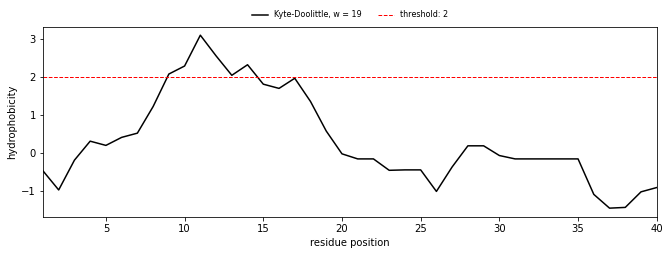

In [46]:
show(seq_pos)

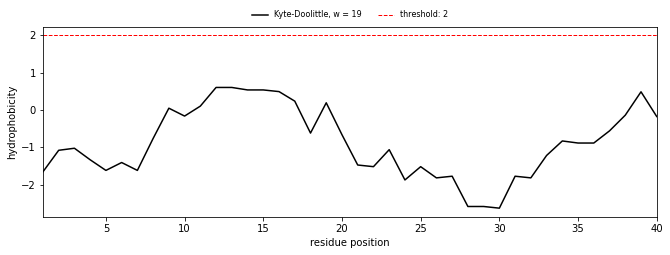

In [47]:
show(seq_neg)